In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error,r2_score

In [2]:
# Import file

In [3]:
df = pd.read_csv("prediction form.csv")
df

,Timestamp,"What is your current CGPA, as of your last completed semester?",Previous CGPA,Total units taken (concluded semester),Average CA score,Proportion of higher-unit courses,Preparedness/attitude to tests,Attitude to assignments,Procrastination tendency,Study hours (course work),...,Extracurricular hours,Access to past questions,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20
0,2026/09/13 11:05:16 AM GMT+1,2.22,2.50,18,20,5,4,3.0,2.0,15,...,NaN,Yes,2.50,45.0,2.11,No,3.0,Yes,Yes,2.14
1,2026/09/13 11:14:55 AM GMT+1,2.10,2.32,18,20,5,3,3.0,2.0,15,...,5,Yes,2.50,45.0,2.11,No,NaN,No,Yes,2.20
2,2026/09/14 1:29:28 PM GMT+1,4.63,4.65,22,25,7,5,5.0,3.0,2,...,1,Yes,4.85,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2026/09/14 1:39:51 PM GMT+1,2.42,2.32,104 units,15,4,3,4.0,4.0,Barely an hr sometimes and some 2hrs,...,4,Yes,2.83,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2026/09/14 1:43:35 PM GMT+1,3.6,3.8,8,23,4,2,3.0,3.0,8,...,14,Yes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,2026/09/14 1:52:58 PM GMT+1,2.99,3.01,18,"69, cant remember",Dont know,3,4.0,3.0,2hr,...,The whole week,"Nope, na we be first set and them dey show us ...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,2026/09/14 2:21:12 PM GMT+1,4.61,4.64,7,17,5,3,5.0,3.0,6,...,4,Yes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,2026/09/14 2:34:31 PM GMT+1,4.57,4.50,20,NaN,4,2,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,2026/09/14 2:36:09 PM GMT+1,3.4,3.35,18,20,2,3,4.0,4.0,1,...,0,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,2026/09/14 2:48:14 PM GMT+1,No idea,No idea,3 unit,I didn’t write cause I’m on IT,1,3,5.0,4.0,78 hours,...,Non,Yes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
df.shape

(41, 21)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41 entries, 0 to 40
Data columns (total 21 columns):
 #   Column                                                          Non-Null Count  Dtype  
---  ------                                                          --------------  -----  
 0   Timestamp                                                       41 non-null     str    
 1   What is your current CGPA, as of your last completed semester?  41 non-null     str    
 2   Previous CGPA                                                   41 non-null     str    
 3   Total units taken (concluded semester)                          41 non-null     str    
 4   Average CA score                                                40 non-null     str    
 5   Proportion of higher-unit courses                               41 non-null     str    
 6   Preparedness/attitude to tests                                  41 non-null     int64  
 7   Attitude to assignments                                         40

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Preparedness/attitude to tests,41.0,3.560976,0.867432,2.00,3.000,3.000,4.000,5.00
Attitude to assignments,40.0,4.150000,0.802240,2.00,4.000,4.000,5.000,5.00
Procrastination tendency,40.0,3.150000,1.075365,1.00,2.000,3.000,4.000,5.00
Attendance rate,40.0,6.050000,7.867329,3.00,4.000,5.000,5.000,50.00
Unnamed: 13,4.0,3.170000,1.130752,2.50,2.500,2.665,3.335,4.85
Unnamed: 14,2.0,45.000000,0.000000,45.00,45.000,45.000,45.000,45.00
Unnamed: 15,2.0,2.110000,0.000000,2.11,2.110,2.110,2.110,2.11
Unnamed: 17,1.0,3.000000,NaN,3.00,3.000,3.000,3.000,3.00
Unnamed: 20,2.0,2.170000,0.042426,2.14,2.155,2.170,2.185,2.20


In [6]:
df.isnull().sum()

Timestamp                                                          0
What is your current CGPA, as of your last completed semester?     0
Previous CGPA                                                      0
Total units taken (concluded semester)                             0
Average CA score                                                   1
Proportion of higher-unit courses                                  0
Preparedness/attitude to tests                                     0
Attitude to assignments                                            1
Procrastination tendency                                           1
Study hours (course work)                                          2
Attendance rate                                                    1
Extracurricular hours                                              4
Access to past questions                                           1
Unnamed: 13                                                       37
Unnamed: 14                       

In [7]:
df.columns

Index(['Timestamp',
       'What is your current CGPA, as of your last completed semester?',
       'Previous CGPA', 'Total units taken (concluded semester)',
       'Average CA score', 'Proportion of higher-unit courses',
       'Preparedness/attitude to tests', 'Attitude to assignments',
       'Procrastination tendency', 'Study hours (course work)',
       'Attendance rate', 'Extracurricular hours', 'Access to past questions',
       'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16',
       'Unnamed: 17', 'Unnamed: 18', 'Unnamed: 19', 'Unnamed: 20'],
      dtype='str')

In [8]:
df_clean = df.drop(columns = ['Timestamp','Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16',
       'Unnamed: 17', 'Unnamed: 18', 'Unnamed: 19', 'Unnamed: 20'])

In [9]:
df_clean.head(10)

,"What is your current CGPA, as of your last completed semester?",Previous CGPA,Total units taken (concluded semester),Average CA score,Proportion of higher-unit courses,Preparedness/attitude to tests,Attitude to assignments,Procrastination tendency,Study hours (course work),Attendance rate,Extracurricular hours,Access to past questions
0,2.22,2.50,18,20,5,4,3.0,2.0,15,50.0,NaN,Yes
1,2.10,2.32,18,20,5,3,3.0,2.0,15,25.0,5,Yes
2,4.63,4.65,22,25,7,5,5.0,3.0,2,5.0,1,Yes
3,2.42,2.32,104 units,15,4,3,4.0,4.0,Barely an hr sometimes and some 2hrs,4.0,4,Yes
4,3.6,3.8,8,23,4,2,3.0,3.0,8,4.0,14,Yes
5,2.99,3.01,18,"69, cant remember",Dont know,3,4.0,3.0,2hr,5.0,The whole week,"Nope, na we be first set and them dey show us ..."
6,4.61,4.64,7,17,5,3,5.0,3.0,6,4.0,4,Yes
7,4.57,4.50,20,NaN,4,2,NaN,NaN,NaN,NaN,NaN,NaN
8,3.4,3.35,18,20,2,3,4.0,4.0,1,5.0,0,No
9,No idea,No idea,3 unit,I didn’t write cause I’m on IT,1,3,5.0,4.0,78 hours,4.0,Non,Yes


In [10]:
df_clean = df_clean.rename(columns= {
    "What is your current CGPA, as of your last completed semester?":"Current CGPA",
    "Total units taken (concluded semester)": "Total units",
    "Proportion of higher-unit courses" : "Higher-unit Courses",
    "Preparedness/attitude to tests" :  "Test_Preparation",
    "Study hours (course work)" : "Study hours",
    "Access to past questions" : "Past Questions"
})

In [11]:
df_clean

,Current CGPA,Previous CGPA,Total units,Average CA score,Higher-unit Courses,Test_Preparation,Attitude to assignments,Procrastination tendency,Study hours,Attendance rate,Extracurricular hours,Past Questions
0,2.22,2.50,18,20,5,4,3.0,2.0,15,50.0,NaN,Yes
1,2.10,2.32,18,20,5,3,3.0,2.0,15,25.0,5,Yes
2,4.63,4.65,22,25,7,5,5.0,3.0,2,5.0,1,Yes
3,2.42,2.32,104 units,15,4,3,4.0,4.0,Barely an hr sometimes and some 2hrs,4.0,4,Yes
4,3.6,3.8,8,23,4,2,3.0,3.0,8,4.0,14,Yes
5,2.99,3.01,18,"69, cant remember",Dont know,3,4.0,3.0,2hr,5.0,The whole week,"Nope, na we be first set and them dey show us ..."
6,4.61,4.64,7,17,5,3,5.0,3.0,6,4.0,4,Yes
7,4.57,4.50,20,NaN,4,2,NaN,NaN,NaN,NaN,NaN,NaN
8,3.4,3.35,18,20,2,3,4.0,4.0,1,5.0,0,No
9,No idea,No idea,3 unit,I didn’t write cause I’m on IT,1,3,5.0,4.0,78 hours,4.0,Non,Yes


In [13]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 41 entries, 0 to 40
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Current CGPA              41 non-null     str    
 1   Previous CGPA             41 non-null     str    
 2   Total units               41 non-null     str    
 3   Average CA score          40 non-null     str    
 4   Higher-unit Courses       41 non-null     str    
 5   Test_Preparation          41 non-null     int64  
 6   Attitude to assignments   40 non-null     float64
 7   Procrastination tendency  40 non-null     float64
 8   Study hours               39 non-null     str    
 9   Attendance rate           40 non-null     float64
 10  Extracurricular hours     37 non-null     str    
 11  Past Questions            40 non-null     str    
dtypes: float64(3), int64(1), str(8)
memory usage: 5.1 KB


In [12]:
df_clean.describe(include="number")

,Test_Preparation,Attitude to assignments,Procrastination tendency,Attendance rate
count,41.000000,40.00000,40.000000,40.000000
mean,3.560976,4.15000,3.150000,6.050000
std,0.867432,0.80224,1.075365,7.867329
min,2.000000,2.00000,1.000000,3.000000
25%,3.000000,4.00000,2.000000,4.000000
50%,3.000000,4.00000,3.000000,5.000000
75%,4.000000,5.00000,4.000000,5.000000
max,5.000000,5.00000,5.000000,50.000000


In [13]:
df_clean.duplicated().sum()

np.int64(0)

In [14]:
df_clean.columns

Index(['Current CGPA', 'Previous CGPA', 'Total units', 'Average CA score',
       'Higher-unit Courses', 'Test_Preparation', 'Attitude to assignments',
       'Procrastination tendency', 'Study hours', 'Attendance rate',
       'Extracurricular hours', 'Past Questions'],
      dtype='str')

In [17]:
# for i in ['Study hours (course work)','Extracurricular hours']:
#     df[i].fillna(df[i].mode()[0])
    

In [18]:
# df['Average CA score'] = df['Average CA score'].fillna(df['Average CA score'].mode()[0])
# df['Study hours (course work)'] = df['Study hours (course work)'].fillna(df['Study hours (course work)'].mode()[0])
# df['Extracurricular hours'] = df['Extracurricular hours'].fillna(df['Extracurricular hours'].mode()[0])

In [19]:
# for i in ['Procrastination tendency','Attitude to assignments','Attendance rate']:
#     df[i].fillna(df[i].median())
    

In [15]:
df_clean.isnull().sum()

Current CGPA                0
Previous CGPA               0
Total units                 0
Average CA score            1
Higher-unit Courses         0
Test_Preparation            0
Attitude to assignments     1
Procrastination tendency    1
Study hours                 2
Attendance rate             1
Extracurricular hours       4
Past Questions              1
dtype: int64

In [21]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 41 entries, 0 to 40
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Current CGPA              41 non-null     str    
 1   Previous CGPA             41 non-null     str    
 2   Total units               41 non-null     str    
 3   Average CA score          40 non-null     str    
 4   Higher-unit Courses       41 non-null     str    
 5   Test_Preparation          41 non-null     int64  
 6   Attitude to assignments   40 non-null     float64
 7   Procrastination tendency  40 non-null     float64
 8   Study hours               39 non-null     str    
 9   Attendance rate           40 non-null     float64
 10  Extracurricular hours     37 non-null     str    
 11  Past Questions            40 non-null     str    
dtypes: float64(3), int64(1), str(8)
memory usage: 5.1 KB


In [16]:
df_clean["Current CGPA"] = pd.to_numeric(df_clean["Current CGPA"], errors="coerce") #changing the datatype

In [17]:
# print(df_clean["Current CGPA"].unique())

In [18]:
df_clean["Previous CGPA"] = pd.to_numeric(df_clean["Previous CGPA"], errors="coerce") #changing the datatype

In [19]:
# print(df_clean["Previous CGPA"].unique())

In [20]:
df_clean.describe()

,Current CGPA,Previous CGPA,Test_Preparation,Attitude to assignments,Procrastination tendency,Attendance rate
count,38.000000,39.000000,41.000000,40.00000,40.000000,40.000000
mean,3.851579,3.893333,3.560976,4.15000,3.150000,6.050000
std,0.791552,0.731147,0.867432,0.80224,1.075365,7.867329
min,2.100000,2.320000,2.000000,2.00000,1.000000,3.000000
25%,3.347500,3.480000,3.000000,4.00000,2.000000,4.000000
50%,4.010000,4.040000,3.000000,4.00000,3.000000,5.000000
75%,4.570000,4.515000,4.000000,5.00000,4.000000,5.000000
max,4.790000,5.000000,5.000000,5.00000,5.000000,50.000000


In [21]:
df_clean["Average CA score"] = df_clean["Average CA score"].astype(str).str.extract(r"(\d+(?:\.\d+)?)") #Separating the number from string

In [22]:
df_clean["Average CA score"] = pd.to_numeric(df["Average CA score"], errors="coerce") #Changing datatype

In [23]:
#for Total Unit 

In [24]:
df_clean["Total units"] = df_clean["Total units"].astype(str).str.extract(r"(\d+(?:\.\d+)?)") #Separating the number from string

In [25]:
df_clean["Total units"] = pd.to_numeric(df_clean["Total units"], errors="coerce")  #Changing datatype

In [26]:
#for Study hours

In [27]:
df_clean["Study hours"] = df_clean["Study hours"].astype(str).str.extract(r"(\d+(?:\.\d+)?)")  #Separating the number from string

In [28]:
df_clean["Study hours"] = pd.to_numeric(df_clean["Study hours"])  #Changing datatype

In [29]:
#Higher-unit Courses
df_clean["Higher-unit Courses"] = pd.to_numeric(df_clean["Higher-unit Courses"], errors="coerce") 

#Extracurricular hours
df_clean["Extracurricular hours"] = df_clean["Extracurricular hours"].astype(str).str.extract(r"(\d+(?:\.\d+)?)")
df_clean["Extracurricular hours"] = pd.to_numeric(df_clean["Extracurricular hours"], errors="coerce") 



In [30]:
#print(df_clean["Extracurricular hours"].unique())

In [31]:
df_clean["Past Questions"] = df_clean["Past Questions"].astype(str).str.lower()

df_clean["Past Questions"] = df_clean["Past Questions"].replace("nope, na we be first set and them dey show us shege", "no")
df_clean["Past Questions"] = df_clean["Past Questions"].str.strip() #for clearing out space in the column

In [32]:
df_clean["Past Questions"].value_counts()

Past Questions
yes      28
no       11
maybe     1
Name: count, dtype: int64

In [33]:
df_clean

,Current CGPA,Previous CGPA,Total units,Average CA score,Higher-unit Courses,Test_Preparation,Attitude to assignments,Procrastination tendency,Study hours,Attendance rate,Extracurricular hours,Past Questions
0,2.22,2.50,18,20.00,5.0,4,3.0,2.0,15.0,50.0,NaN,yes
1,2.10,2.32,18,20.00,5.0,3,3.0,2.0,15.0,25.0,5.0,yes
2,4.63,4.65,22,25.00,7.0,5,5.0,3.0,2.0,5.0,1.0,yes
3,2.42,2.32,104,15.00,4.0,3,4.0,4.0,2.0,4.0,4.0,yes
4,3.60,3.80,8,23.00,4.0,2,3.0,3.0,8.0,4.0,14.0,yes
5,2.99,3.01,18,NaN,NaN,3,4.0,3.0,2.0,5.0,NaN,no
6,4.61,4.64,7,17.00,5.0,3,5.0,3.0,6.0,4.0,4.0,yes
7,4.57,4.50,20,NaN,4.0,2,NaN,NaN,NaN,NaN,NaN,NaN
8,3.40,3.35,18,20.00,2.0,3,4.0,4.0,1.0,5.0,0.0,no
9,NaN,NaN,3,NaN,1.0,3,5.0,4.0,78.0,4.0,NaN,yes


In [40]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 41 entries, 0 to 40
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Current CGPA              38 non-null     float64
 1   Previous CGPA             39 non-null     float64
 2   Total units               41 non-null     int64  
 3   Average CA score          36 non-null     float64
 4   Higher-unit Courses       37 non-null     float64
 5   Test_Preparation          41 non-null     int64  
 6   Attitude to assignments   40 non-null     float64
 7   Procrastination tendency  40 non-null     float64
 8   Study hours               38 non-null     float64
 9   Attendance rate           40 non-null     float64
 10  Extracurricular hours     29 non-null     float64
 11  Past Questions            40 non-null     str    
dtypes: float64(9), int64(2), str(1)
memory usage: 4.1 KB


In [34]:
df_clean.isnull().sum()

Current CGPA                 3
Previous CGPA                2
Total units                  0
Average CA score             5
Higher-unit Courses          4
Test_Preparation             0
Attitude to assignments      1
Procrastination tendency     1
Study hours                  3
Attendance rate              1
Extracurricular hours       12
Past Questions               1
dtype: int64

In [35]:
for i in ["Current CGPA","Previous CGPA", "Average CA score","Higher-unit Courses"]:
    df_clean[i] = df_clean[i].fillna(df_clean[i].mean())

In [36]:
for i in ["Extracurricular hours","Study hours","Attitude to assignments","Procrastination tendency","Attendance rate"]:
    df_clean[i] = df_clean[i].fillna(df_clean[i].median())

In [37]:
df_clean["Past Questions"].value_counts()

Past Questions
yes      28
no       11
maybe     1
Name: count, dtype: int64

In [38]:
encoder = LabelEncoder()

In [39]:
df_clean["Past Questions"] = encoder.fit_transform(df_clean["Past Questions"])

In [40]:
df_clean["Past Questions"].value_counts()

Past Questions
2    28
1    11
3     1
0     1
Name: count, dtype: int64

In [41]:
df_clean.isnull().sum()

Current CGPA                0
Previous CGPA               0
Total units                 0
Average CA score            0
Higher-unit Courses         0
Test_Preparation            0
Attitude to assignments     0
Procrastination tendency    0
Study hours                 0
Attendance rate             0
Extracurricular hours       0
Past Questions              0
dtype: int64

In [42]:
# df_clean

In [43]:
df_clean["Current CGPA"].skew()

np.float64(-0.8403807899631861)

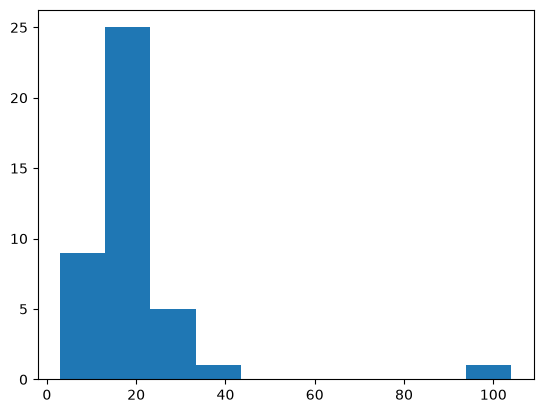

In [44]:
plt.hist(df_clean["Total units"])
plt.show()

In [43]:
#traning model

In [45]:
df_clean.columns

Index(['Current CGPA', 'Previous CGPA', 'Total units', 'Average CA score',
       'Higher-unit Courses', 'Test_Preparation', 'Attitude to assignments',
       'Procrastination tendency', 'Study hours', 'Attendance rate',
       'Extracurricular hours', 'Past Questions'],
      dtype='str')

In [46]:
features = [
    'Previous CGPA', 
    'Total units', 
    'Average CA score',
    'Higher-unit Courses', 
    'Test_Preparation', 
    'Attitude to assignments',
    'Procrastination tendency', 
    'Study hours',
    'Attendance rate',
    'Extracurricular hours', 
    'Past Questions'
]

x = df_clean[features]
y = df_clean['Current CGPA']

In [47]:
x_train, x_test, y_train, y_test = train_test_split(x,y, random_state = 42, test_size = 0.2)

In [47]:
# x_train # print(x_test) 

In [48]:
# y_test

In [48]:
# Making use of Pipeline with LinearRegression

linear_model = Pipeline([
    ("scalar", StandardScaler()),
    ("model", LinearRegression())
])

In [49]:
linear_model.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scalar', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['Previous CGPA','Total units','Average CA score',...,'Attendance rate', 'Extracurricular hours','Past Questions']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [50]:
y_pred = linear_model.predict(x_test)
print(y_pred)

[3.56743723 2.95181281 3.45119063 2.7449276  3.85588358 4.70120653
 4.01143047 4.17354498 4.25843515]


In [58]:
# x_train

In [57]:
df_compare = pd.DataFrame({"Test CGPA":y_test.values, "Predicted CGPA":y_pred.round(2)})

df_compare

,Test CGPA,Predicted CGPA
0,2.17,3.57
1,3.01,2.95
2,3.40,3.45
3,2.94,2.74
4,3.60,3.86
5,4.63,4.70
6,3.96,4.01
7,3.89,4.17
8,4.40,4.26


In [60]:
mean_error = mean_absolute_error(y_test, y_pred)
mean_squared = mean_squared_error(y_test, y_pred)
print("Mean_err",mean_error)
print("Mean_squared",mean_squared)

Mean_err 0.27839087236206594
Mean_squared 0.24116894522486745


In [59]:
# df_clean[['Current CGPA_t', 'Previous CGPA_t', 'Total units_t', 'Average CA score_t',
#        'Higher-unit Courses_t', 'Test_Preparation_t', 'Attitude to assignments_t',
#        'Procrastination tendency_t', 'Study hours_t', 'Attendance rate_t',
#        'Extracurricular hours_t', 'Past Questions_t']] = scaler.fit_transform(df_clean[['Current CGPA', 'Previous CGPA', 'Total units', 'Average CA score',
#        'Higher-unit Courses_t', 'Test_Preparation_t', 'Attitude to assignments',
#        'Procrastination tendency_t', 'Study hours_t', 'Attendance rate_t',
#        'Extracurricular hours_t', 'Past Questions_t']])

In [66]:
# df_clean